<a href="https://colab.research.google.com/github/SubeenJung0228/Problem-Set-econ-3916/blob/main/Problem%20Set%204/Econ_3916_PS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [2]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others
N_IRRELEVANT = 12            # predictors with a true coefficient of zero
KINK = 30.0                  # '000 sq ft: above this, revenue grows more slowly with area

In [3]:
def true_revenue(df):
    # slope 9 per '000 sq ft up to the kink, slope 3 after it
    area_effect = 9 * df['floor_area'] - 6 * np.maximum(df['floor_area'] - KINK, 0)
    return 40 + area_effect + 1.5 * df['foot_traffic'] + 1.2 * df['median_income'] + 2 * df['years_open']

def make_stores(n):
    df = pd.DataFrame()
    df['floor_area'] = rng.lognormal(np.log(20), 0.5, n)                  # '000 sq ft
    df['foot_traffic'] = np.clip(15 + df['floor_area'] + rng.normal(0, 8, n), 2, None)   # '000 visits
    df['median_income'] = np.clip(rng.normal(70, 15, n), 25, None)         # $'000
    df['years_open'] = rng.integers(0, 31, n)
    # almost exactly 0.6*floor_area + 0.25*foot_traffic -> the collinear one (true effect = 0)
    df['staff_count'] = 0.6 * df['floor_area'] + 0.25 * df['foot_traffic'] + rng.normal(0, 0.8, n)
    # useless predictors (true effect = 0)
    for i in range(N_IRRELEVANT):
        df[f'junk_{i+1}'] = rng.normal(50, 10, n)
    # noise gets bigger for bigger stores (sd = 0.9 * floor area)
    df['revenue'] = true_revenue(df) + rng.normal(0, 0.9 * df['floor_area'])
    return df

stores = make_stores(N_STORES)
predictors = [c for c in stores.columns if c != 'revenue']
X = stores[predictors]
y = stores['revenue']

stores.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
floor_area,400.0,22.38,11.61,5.54,14.33,20.17,26.93,85.86
foot_traffic,400.0,36.96,13.86,2.53,27.09,35.32,44.42,101.79
median_income,400.0,69.89,14.76,25.00,60.96,70.11,79.20,117.68
years_open,400.0,15.23,9.26,0.00,7.00,15.00,24.00,30.00
staff_count,400.0,22.60,10.00,4.66,15.79,20.87,26.55,75.54
junk_1,400.0,49.12,9.65,19.52,42.54,50.13,55.50,78.57
junk_2,400.0,50.54,10.49,19.36,43.98,50.85,57.88,77.67
junk_3,400.0,50.21,10.09,21.38,43.23,49.73,57.53,80.60
junk_4,400.0,49.98,9.48,22.51,43.35,49.91,56.32,80.89
junk_5,400.0,50.73,9.94,28.05,43.71,50.68,57.21,78.45


*The data-generating process, recorded: every predictor and the true revenue equation.*

The data-generating process uses 400 stores with a random seed of 42. Revenue depends on floor area, foot traffic, median income, and years open. Floor area follows a lognormal distribution with a median of 20 and a log-SD of 0.5, so a few stores are much larger than the others. Foot traffic depends on floor area plus random noise, while median income follows a normal distribution with a mean of 70 and a standard deviation of 15. Both variables have minimum values. Years open is an integer from 0 to 30.

The true coefficients are 1.5 for foot traffic, 1.2 for median income, and 2.0 for years open. Floor area has a nonlinear effect on revenue. Its coefficient is 9 up to 30,000 sq ft and 3 above that point. The error term also grows with store size, with a standard deviation equal to 0.9 times floor area.

There are also 13 additional predictors: **staff_count** and **junk_1** to **junk_12**. Staff count is highly correlated with floor area and foot traffic, but its true coefficient is 0. The twelve junk variables are independent random variables with no effect on revenue. Their true coefficients are also 0. The **true_revenue()** function stores the actual revenue equation and provides a way to check the results in Phase 3.

### Step 1.2: Fit it the way they did (12 pts)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# fit on everything, like the old analyst did
full = sm.OLS(y, sm.add_constant(X)).fit()
print("In-sample R^2:", round(full.rsquared, 3))

# now split: train on 75%, test on the other 25%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
split_model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
test_r2 = r2_score(y_test, split_model.predict(sm.add_constant(X_test)))
print("Train R^2:", round(split_model.rsquared, 3))
print("Test R^2:", round(test_r2, 3))
print("Gap:", round(split_model.rsquared - test_r2, 3))

# one split could be lucky, so try 500 different splits
gaps = []
test_scores = []
for seed in range(500):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, random_state=seed)
    m = sm.OLS(ya, sm.add_constant(Xa)).fit()
    t = r2_score(yb, m.predict(sm.add_constant(Xb)))
    test_scores.append(t)
    gaps.append(m.rsquared - t)

print("\nOver 500 splits:")
print("average test R^2:", round(np.mean(test_scores), 3))
print("5th to 95th percentile:", np.round(np.percentile(test_scores, [5, 95]), 3))
print("average gap:", round(np.mean(gaps), 3))

In-sample R^2: 0.908
Train R^2: 0.92
Test R^2: 0.863
Gap: 0.057

Over 500 splits:
average test R^2: 0.895
5th to 95th percentile: [0.853 0.929]
average gap: 0.014


*Your answer here.*


When I fit OLS with all 17 predictors on the 400 stores, the in-sample R² was 0.908. However, the model performed worse on new data. With a 75/25 train-test split, the training R² was 0.920 and the test R² was 0.863, a gap of 0.057. Since one split may give misleading results, I repeated the process 500 times. The average test R² was 0.895, with values from 0.853 to 0.929 in the 5th to 95th percentile range. The average gap was 0.014.

This suggests that the model explains about 90% of the variation in revenue for new stores, but its performance can vary by around 0.04. However, R² does not tell the whole story. A model can have a high R² and still make consistent errors for the largest stores. Phase 2 looks more closely at these errors.

### Step 1.3: Say what R-squared is (8 pts)

In [5]:
# add 3 columns of pure noise
noise = rng.normal(size=(N_STORES, 3))
X_noise = X.copy()
X_noise['noise_1'] = noise[:, 0]
X_noise['noise_2'] = noise[:, 1]
X_noise['noise_3'] = noise[:, 2]

noise_model = sm.OLS(y, sm.add_constant(X_noise)).fit()

print("R^2 before:", round(full.rsquared, 5), " after:", round(noise_model.rsquared, 5))
print("Adj R^2 before:", round(full.rsquared_adj, 5), " after:", round(noise_model.rsquared_adj, 5))

R^2 before: 0.90762  after: 0.90773
Adj R^2 before: 0.90351  after: 0.90286


*Your answer here.*

**Why in-sample R² cannot decrease when a predictor is added**

OLS chooses coefficients to minimize RSS. Since R² is calculated as 1 − RSS/TSS and TSS stays fixed, a lower RSS means a higher R². The larger model includes the smaller model as a special case because the new coefficient can be set to zero. Therefore, adding a predictor can only keep R² the same or increase it. In practice, R² usually increases slightly because even random noise can have some correlation with the residuals in a finite sample.

**What this means for choosing models**

If we compare models only by in-sample R², we will always prefer the model with more predictors, even if the extra variables do not improve predictions on new data. R² measures how well the model fits the current data, not how accurately it predicts future revenue. Adjusted R² accounts for the number of predictors and penalizes unnecessary variables. However, it is still based on the training data. To choose a better model, we need to test its performance on data it has not seen (Phase 3).

**Demonstration**

Adding three columns of random noise increased R² from 0.90762 to 0.90773 (+0.00011), even though these variables had no real relationship with revenue. However, adjusted R² decreased from 0.90351 to 0.90286 (−0.00065). This shows that the extra variables did not improve the model enough to justify the additional parameters.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

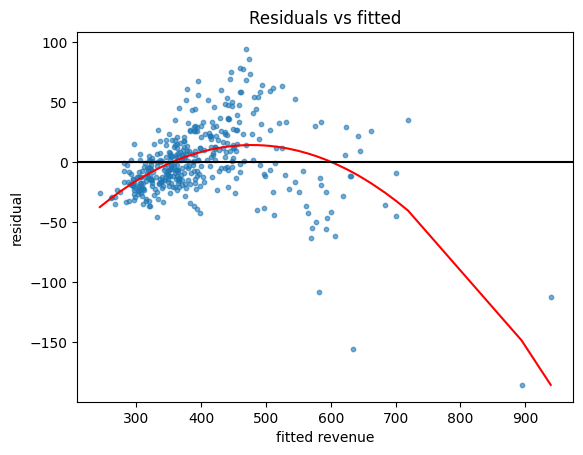

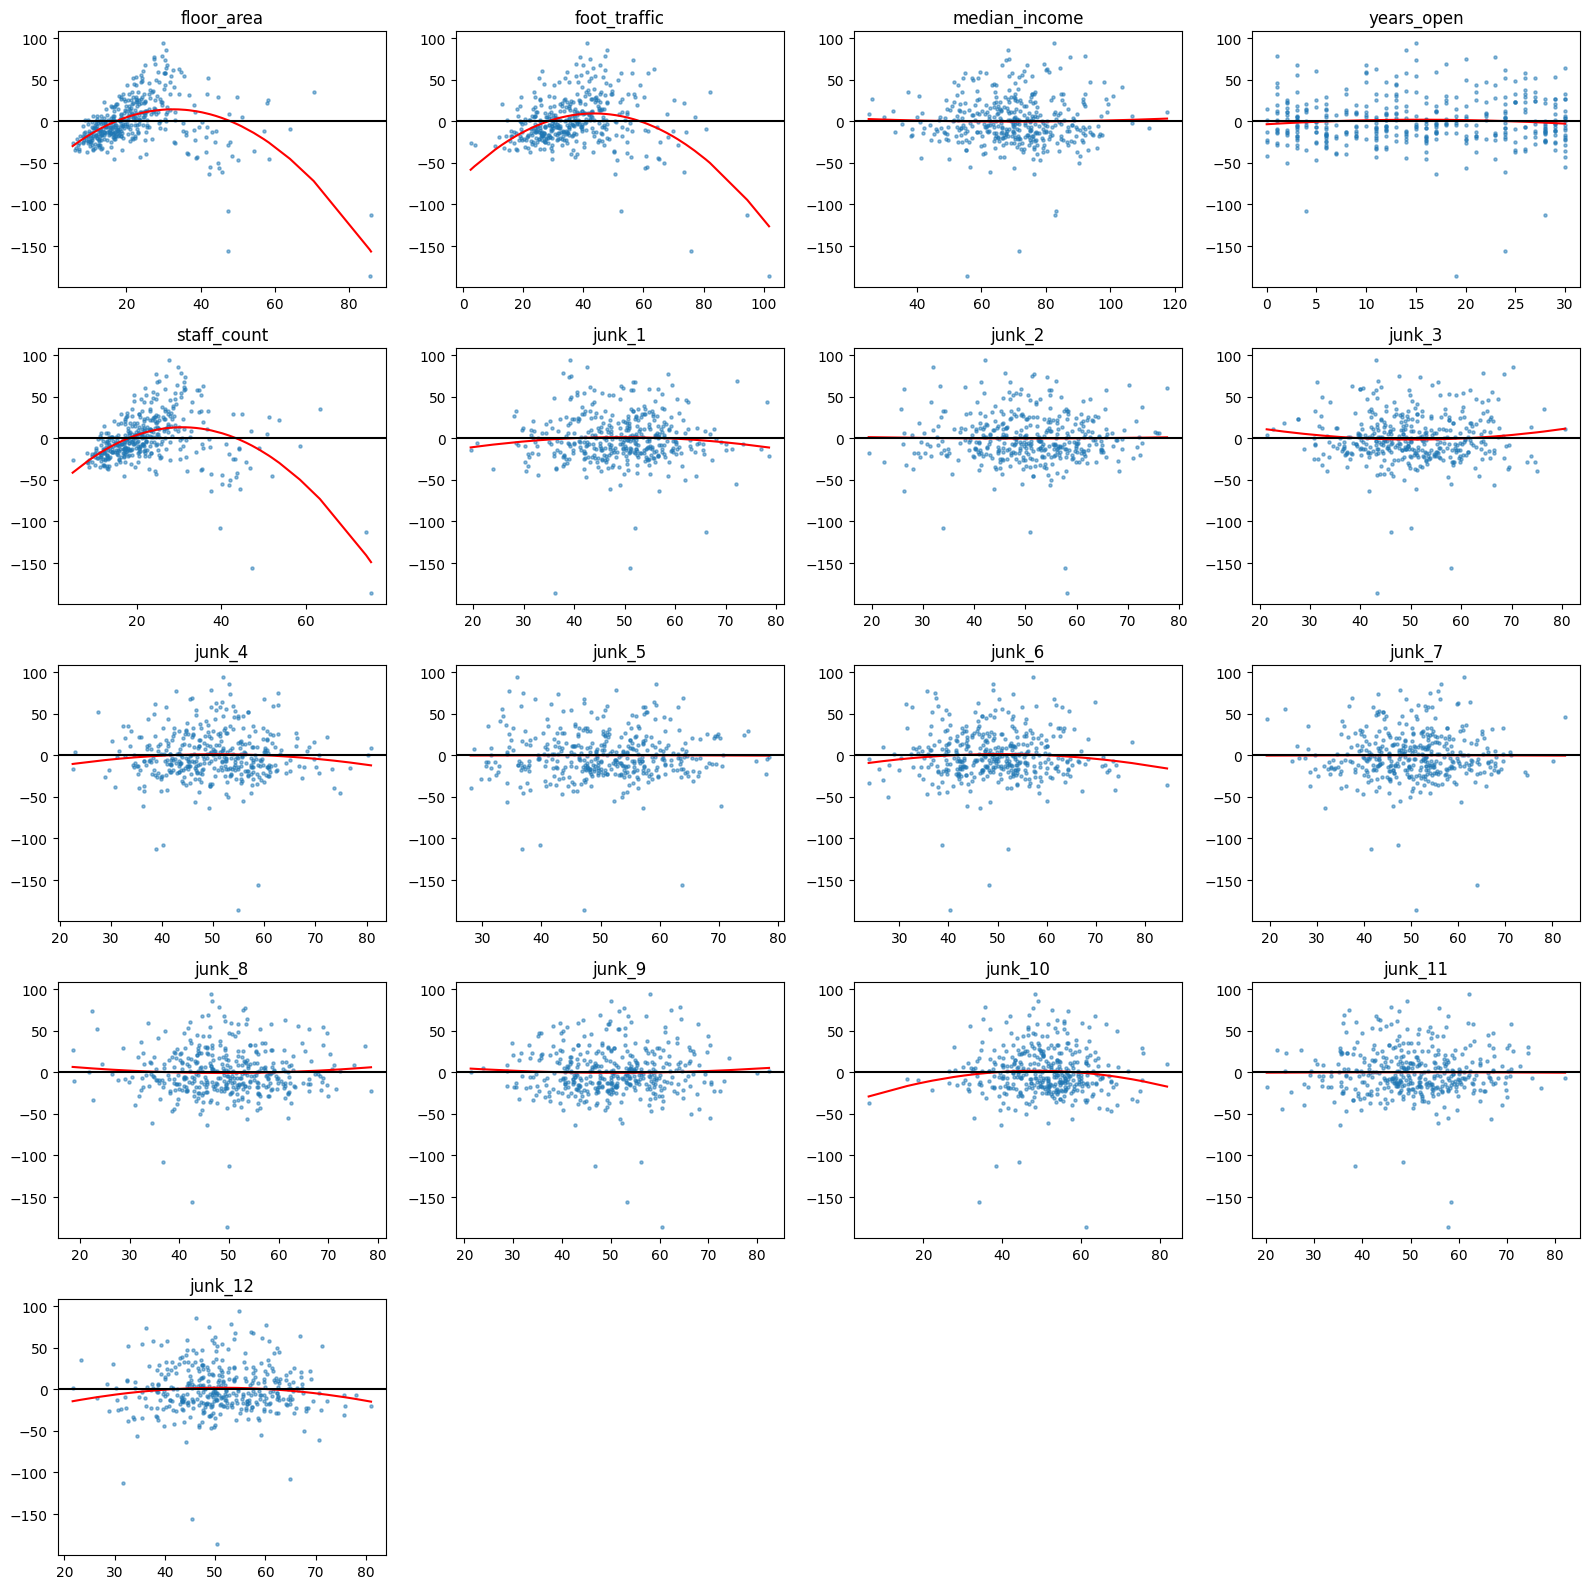

Residual SD by store size:
floor_area
smallest    10.8
2           13.9
3           18.5
4           24.5
largest     50.9
dtype: float64
Breusch-Pagan p-value: 3.9077169466237504e-13

floor_area SE, normal: 1.142  robust: 1.366

floor_area^2 coef: -0.062  t-stat: -6.6

Stores with Cook's D > 4/n: 24
their median floor area: 30.6  vs all stores: 20.2


/tmp/ipykernel_47554/1411755621.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(resid.groupby(size_group).std().round(1))


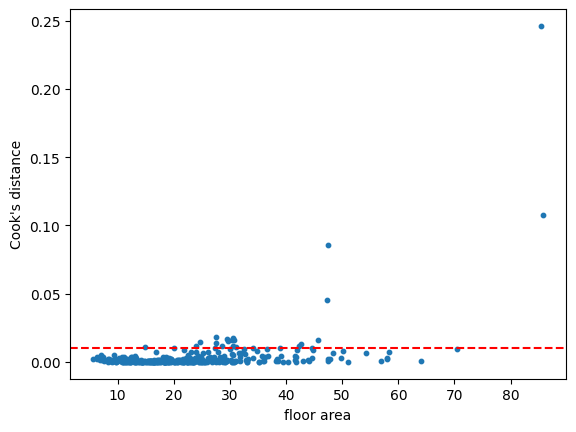

               all stores  without influential
floor_area           5.84                 7.92
foot_traffic         0.90                 1.77
median_income        1.12                 1.09
years_open           1.73                 1.95


In [6]:
from statsmodels.stats.diagnostic import het_breuschpagan

resid = full.resid
fitted = full.fittedvalues

# residuals vs fitted values (red line = quadratic trend so curves are easy to see)
plt.scatter(fitted, resid, s=10, alpha=0.6)
xs = np.sort(fitted)
plt.plot(xs, np.polyval(np.polyfit(fitted, resid, 2), xs), color='red')
plt.axhline(0, color='black')
plt.xlabel('fitted revenue')
plt.ylabel('residual')
plt.title('Residuals vs fitted')
plt.show()

# residuals vs each predictor
fig, axes = plt.subplots(5, 4, figsize=(16, 16))
axes = axes.flatten()
for i, col in enumerate(predictors):
    axes[i].scatter(X[col], resid, s=5, alpha=0.5)
    xs = np.sort(X[col])
    axes[i].plot(xs, np.polyval(np.polyfit(X[col], resid, 2), xs), color='red')
    axes[i].axhline(0, color='black')
    axes[i].set_title(col)
for j in range(len(predictors), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

# Problem 1: non-constant variance
size_group = pd.qcut(X['floor_area'], 5, labels=['smallest', '2', '3', '4', 'largest'])
print("Residual SD by store size:")
print(resid.groupby(size_group).std().round(1))
bp = het_breuschpagan(resid, sm.add_constant(X))
print("Breusch-Pagan p-value:", bp[1])

robust = sm.OLS(y, sm.add_constant(X)).fit(cov_type='HC3')
print("\nfloor_area SE, normal:", round(full.bse['floor_area'], 3), " robust:", round(robust.bse['floor_area'], 3))

# Problem 2: non-linearity -> does a squared term help?
X_sq = X.copy()
X_sq['floor_area_sq'] = X['floor_area'] ** 2
sq_model = sm.OLS(y, sm.add_constant(X_sq)).fit(cov_type='HC3')
print("\nfloor_area^2 coef:", round(sq_model.params['floor_area_sq'], 3),
      " t-stat:", round(sq_model.tvalues['floor_area_sq'], 1))

# Problem 3: influential points (Cook's distance)
cooks = full.get_influence().cooks_distance[0]
cutoff = 4 / N_STORES
big_cooks = X.index[cooks > cutoff]
print("\nStores with Cook's D > 4/n:", len(big_cooks))
print("their median floor area:", round(X.loc[big_cooks, 'floor_area'].median(), 1),
      " vs all stores:", round(X['floor_area'].median(), 1))

plt.scatter(X['floor_area'], cooks, s=10)
plt.axhline(cutoff, color='red', linestyle='--')
plt.xlabel('floor area')
plt.ylabel("Cook's distance")
plt.show()

# refit without them and compare coefficients
no_infl = sm.OLS(y.drop(big_cooks), sm.add_constant(X.drop(big_cooks))).fit()
print(pd.DataFrame({'all stores': full.params, 'without influential': no_infl.params}).iloc[1:5].round(2))

*Your answer here.*

**1. Non-constant variance (heteroskedasticity)**

The residual plots show a funnel shape, and residual SD increases from \$10.8k for the smallest stores to $50.9k for the largest. The Breusch-Pagan test also rejects constant variance (p ≈ 4 × 10⁻¹³).
- Assumption violated: Homoskedasticity (constant error variance).
- Estimate: OLS estimates are still unbiased as long as E[ε | X] = 0, but they are no longer the most efficient.
- Standard error: Classical SEs underestimate uncertainty. For floor_area, the classical SE is 1.142 compared with 1.366 using HC3 robust SEs. Robust SEs fix this without changing the coefficients.


**2. Nonlinear relationship**

The residual plots show a curved pattern, with positive residuals in the middle and negative residuals at both ends. Adding floor area squared gives a coefficient of −0.062 with a robust t-statistic of −6.6.
- Assumption violated: Linearity and correct model specification (E[ε | X] = 0).
- Estimate: The area slope of 5.84 is biased because the true effect is 9 below 30k sq ft and 3 above. The linear model overestimates the effect for larger stores.
- Standard error: It may look reasonable but measures precision around the wrong estimate. Robust SEs cannot fix model misspecification.


**3. Influential observations**

24 stores have Cook's D above 4/n, and most are large stores. Their median floor area is 30.6k sq ft compared with 20.2k overall.
- Assumption involved: No direct Gauss-Markov violation, but a small number of observations have a strong influence on the estimates.
- Estimate: The results are sensitive to these stores. Removing them changes the area slope from 5.84 to 7.92 and the foot-traffic slope from 0.90 to 1.77.
- Standard error: Classical SEs do not fully reflect this sensitivity. HC3 partly addresses the issue.


**Conclusion:** We should not remove these stores because they are real observations. The main problem is that the linear model does not capture their relationship with revenue. The solution is to improve the model in Phase 3, not remove the data.

### Step 2.2: The over-forecast on big stores (15 pts)

/tmp/ipykernel_47554/292752246.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  table = pd.DataFrame({'avg error ($k)': error.groupby(decile).mean(),
/tmp/ipykernel_47554/292752246.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  'avg error (%)': pct_error.groupby(decile).mean()})


            avg error ($k)  avg error (%)
floor_area                               
1                     21.0            7.7
2                     15.6            5.4
3                     10.3            3.3
4                      5.2            1.8
5                     -1.9           -0.2
6                     -9.3           -2.1
7                    -18.7           -4.1
8                    -18.9           -3.7
9                    -29.0           -5.3
10                    29.1            5.3

Top 10% of stores: avg over-forecast 29.1 k, 5.3 %
t-test p-value: 0.0016553907494048009
Top 5% of stores: avg over-forecast 42.6 k


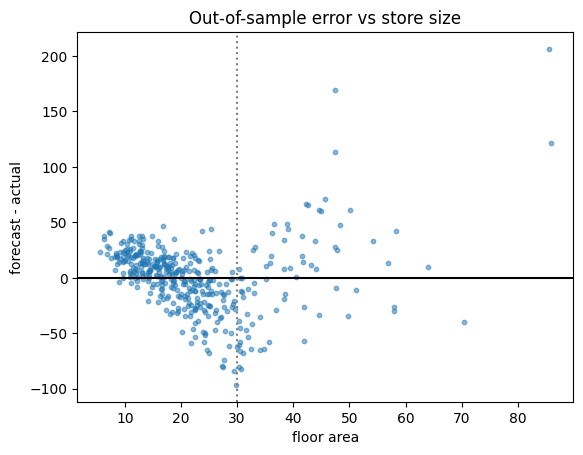


VIF:
staff_count     151.8
floor_area       74.1
foot_traffic     22.4
junk_11           1.1
junk_1            1.1
dtype: float64

floor_area coef with staff_count: 5.84 SE 1.14
floor_area coef without staff_count: 6.75 SE 0.23

bootstrap SD of floor_area coef, with staff_count: 1.31  without: 0.33
staff_count coef negative in 23 % of resamples

CV RMSE with staff_count: 31.92
CV RMSE without staff_count: 31.94


In [7]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor

# predict each store with a model that didn't see it (10-fold CV)
kf = KFold(n_splits=10, shuffle=True, random_state=42)
pred = cross_val_predict(LinearRegression(), X, y, cv=kf)
error = pred - y            # positive = over-forecast
pct_error = 100 * error / y

# average error by size decile
decile = pd.qcut(X['floor_area'], 10, labels=range(1, 11))
table = pd.DataFrame({'avg error ($k)': error.groupby(decile).mean(),
                      'avg error (%)': pct_error.groupby(decile).mean()})
print(table.round(1))

# is the top decile over-forecast on purpose or by chance?
top = decile == 10
print("\nTop 10% of stores: avg over-forecast", round(error[top].mean(), 1), "k,",
      round(pct_error[top].mean(), 1), "%")
print("t-test p-value:", stats.ttest_1samp(error[top], 0).pvalue)
top5 = X['floor_area'] >= X['floor_area'].quantile(0.95)
print("Top 5% of stores: avg over-forecast", round(error[top5].mean(), 1), "k")

plt.scatter(X['floor_area'], error, s=10, alpha=0.5)
plt.axhline(0, color='black')
plt.axvline(KINK, color='grey', linestyle=':')
plt.xlabel('floor area')
plt.ylabel('forecast - actual')
plt.title('Out-of-sample error vs store size')
plt.show()

# VIFs
X_const = sm.add_constant(X)
vif = pd.Series([variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])],
                index=predictors)
print("\nVIF:")
print(vif.sort_values(ascending=False).head(5).round(1))

# with vs without staff_count
X_no_staff = X.drop(columns='staff_count')
model_no_staff = sm.OLS(y, sm.add_constant(X_no_staff)).fit()
print("\nfloor_area coef with staff_count:", round(full.params['floor_area'], 2), "SE", round(full.bse['floor_area'], 2))
print("floor_area coef without staff_count:", round(model_no_staff.params['floor_area'], 2), "SE", round(model_no_staff.bse['floor_area'], 2))

# bootstrap: how much do the coefficients jump around?
coef_with = []
coef_staff = []
coef_without = []
for b in range(500):
    idx = rng.integers(0, N_STORES, N_STORES)
    m1 = sm.OLS(y.iloc[idx], X_const.iloc[idx]).fit()
    m2 = sm.OLS(y.iloc[idx], sm.add_constant(X_no_staff).iloc[idx]).fit()
    coef_with.append(m1.params['floor_area'])
    coef_staff.append(m1.params['staff_count'])
    coef_without.append(m2.params['floor_area'])
print("\nbootstrap SD of floor_area coef, with staff_count:", round(np.std(coef_with), 2),
      " without:", round(np.std(coef_without), 2))
print("staff_count coef negative in", round(100 * np.mean(np.array(coef_staff) < 0)), "% of resamples")

# but do the predictions change?
pred_no_staff = cross_val_predict(LinearRegression(), X_no_staff, y, cv=kf)
print("\nCV RMSE with staff_count:", round(np.sqrt(np.mean((y - pred) ** 2)), 2))
print("CV RMSE without staff_count:", round(np.sqrt(np.mean((y - pred_no_staff) ** 2)), 2))

*Your answer here.*

**1. Is the error systematic by store size?**

Yes. Each store is predicted using 10-fold cross-validation, so the model has not seen that store during training. Positive errors mean over-forecasting.

The errors show a U-shaped pattern across store-size deciles. The smallest decile is over-forecast by \$21.0k (7.7%), while deciles 6–9 are under-forecast by \$9k to $29k. The largest decile is over-forecast by \$29.1k per month (5.3%). This pattern is statistically significant (p ≈ 0.002). For the largest 5% of stores, the over-forecast reaches \$42.6k per month.

The main cause is the nonlinear relationship missed in Step 2.1. The model fits a straight line through mostly mid-sized stores and extends it beyond 30k sq ft, where the true revenue growth rate becomes much smaller. A simple linear test of error against store size would miss this pattern because OLS already makes residuals linearly uncorrelated with the predictors.


**2. The collinear predictor: staff_count**

staff_count has a VIF of 151.8. It also increases the VIF of floor_area (74.1) and foot_traffic (22.4). The junk variables have VIFs close to 1.
- What it damages: The precision of individual coefficients. The SE for floor_area increases from 0.23 without staff_count to 1.14 with it. Its bootstrap SD also increases from 0.33 to 1.31. The model struggles to separate the individual effects of store size, traffic, and staffing.
- What it does not damage: Unbiasedness or prediction accuracy. CV RMSE is almost unchanged: 31.92 with staff_count and 31.94 without.
- Should we remove it? Not simply because its VIF is above 10. Removing it does not fix the over-forecasting problem because collinearity is not the cause. If staffing actually affected revenue, removing it could also create omitted-variable bias. However, since it adds almost no predictive value in this case, we can remove it based on cross-validation results.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

/tmp/ipykernel_47554/1234638744.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[predictors[i] + '*' + predictors[j]] = df[predictors[i]] * df[predictors[j]]
/tmp/ipykernel_47554/1234638744.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[predictors[i] + '*' + predictors[j]] = df[predictors[i]] * df[predictors[j]]
/tmp/ipykernel_47554/1234638744.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining a

                     terms  train RMSE  test RMSE  test RMSE (50 splits)
1: area                  1       37.28      43.82                  39.46
2: + traffic             2       36.45      41.86                  38.33
3: + income, years       4       28.22      36.78                  31.18
4: + area spline         7       23.48      27.27                  25.34
5: + all predictors     20       22.97      27.47                  25.96
6: + squares            37       22.36      26.25                  26.53
7: + core interact.     47       21.47      27.18                  27.30
8: + all interact.     173       14.69      40.47                  41.24


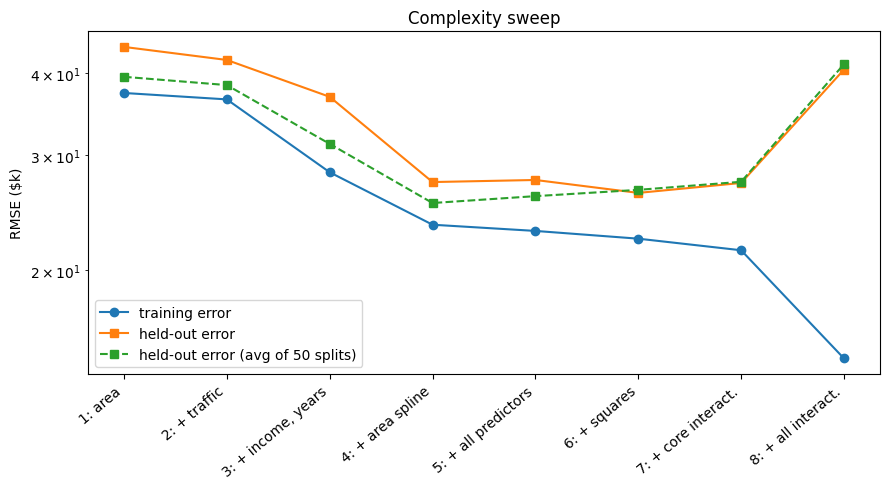

In [8]:
# build every extra term once, then each model just picks columns
knots = np.quantile(X['floor_area'], [0.5, 0.75, 0.9])    # based on floor area only, not revenue

def add_terms(df):
    df = df.copy()
    for k in knots:
        df[f'hinge_{k:.0f}'] = np.maximum(df['floor_area'] - k, 0)
    for col in predictors:
        df[col + '^2'] = df[col] ** 2
    for i in range(len(predictors)):
        for j in range(i + 1, len(predictors)):
            df[predictors[i] + '*' + predictors[j]] = df[predictors[i]] * df[predictors[j]]
    return df

X_all = add_terms(X)

core = ['floor_area', 'foot_traffic', 'median_income', 'years_open']
hinges = [c for c in X_all.columns if c.startswith('hinge')]
others = [c for c in predictors if c not in core]
squares = [c for c in X_all.columns if c.endswith('^2')]
core_inter = [c for c in X_all.columns if '*' in c
              and all(part in core + ['staff_count'] for part in c.split('*'))]
all_inter = [c for c in X_all.columns if '*' in c]

models = {
    '1: area':              ['floor_area'],
    '2: + traffic':         ['floor_area', 'foot_traffic'],
    '3: + income, years':   core,
    '4: + area spline':     core + hinges,
    '5: + all predictors':  core + hinges + others,
    '6: + squares':         core + hinges + others + squares,
    '7: + core interact.':  core + hinges + others + squares + core_inter,
    '8: + all interact.':   core + hinges + others + squares + all_inter,
}

def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))

train_err, test_err, test_err_avg = [], [], []
for name, cols in models.items():
    # the Phase 1 split
    m = LinearRegression().fit(X_all.loc[X_train.index, cols], y_train)
    train_err.append(rmse(y_train, m.predict(X_all.loc[X_train.index, cols])))
    test_err.append(rmse(y_test, m.predict(X_all.loc[X_test.index, cols])))
    # average over 50 splits so the curve isn't just luck
    scores = []
    for seed in range(50):
        Xa, Xb, ya, yb = train_test_split(X_all[cols], y, test_size=0.25, random_state=seed)
        scores.append(rmse(yb, LinearRegression().fit(Xa, ya).predict(Xb)))
    test_err_avg.append(np.mean(scores))

sweep = pd.DataFrame({'terms': [len(c) for c in models.values()], 'train RMSE': train_err,
                      'test RMSE': test_err, 'test RMSE (50 splits)': test_err_avg}, index=models.keys())
print(sweep.round(2))

x = range(1, len(models) + 1)
plt.figure(figsize=(9, 5))
plt.plot(x, train_err, 'o-', label='training error')
plt.plot(x, test_err, 's-', label='held-out error')
plt.plot(x, test_err_avg, 's--', label='held-out error (avg of 50 splits)')
plt.xticks(x, models.keys(), rotation=40, ha='right')
plt.ylabel('RMSE ($k)')
plt.yscale('log')
plt.legend()
plt.title('Complexity sweep')
plt.tight_layout()
plt.show()

*Your answer here.*

**1. The model comparison**

I compared eight models, each with additional predictors and terms. The models range from basic predictors like floor area and foot traffic to splines, squared terms, and interactions. I used the average held-out RMSE from 50 splits to reduce the effect of a lucky split.

Training RMSE decreased at every step, from 37.3 to 14.7. However, held-out RMSE decreased from 39.5 to its lowest value of 25.3 at Model 4, then increased to 26.0, 26.5, 27.3, and finally 41.2 with all interactions.

On the single Phase 1 split, Model 6 had the lowest RMSE (26.25 vs. 27.27). However, the 50-split average shows that Model 4 performs better overall.


**2. Bias-variance tradeoff**

- Models 1–4: High bias. These models are too simple to capture the true relationship. The biggest improvement comes from Model 4, which adds a floor area spline and captures the nonlinear effect of store size.
- Models 5–8: Increasing variance. Adding more predictors and interactions reduces training error but increases held-out error. These extra terms mostly fit noise rather than useful patterns. The gap between training and held-out error grows from about 2 at Model 4 to about 26 at Model 8.


**Conclusion:** Model 4 provides the best balance between bias and variance, with the lowest average held-out RMSE of 25.3.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [9]:
from sklearn.model_selection import RepeatedKFold, cross_val_score

# pick the model with repeated 10-fold CV
rkf = RepeatedKFold(n_splits=10, n_repeats=5, random_state=42)
cv_mean, cv_se = [], []
for name, cols in models.items():
    scores = -cross_val_score(LinearRegression(), X_all[cols], y, cv=rkf, scoring='neg_root_mean_squared_error')
    cv_mean.append(scores.mean())
    cv_se.append(scores.std(ddof=1) / np.sqrt(len(scores)))
cv_table = pd.DataFrame({'CV RMSE': cv_mean, 'SE': cv_se}, index=models.keys())
print(cv_table.round(2))

best_name = cv_table['CV RMSE'].idxmin()
best_cols = models[best_name]
print("\nBest model:", best_name)

# interval: bootstrap the out-of-fold errors
oof = cross_val_predict(LinearRegression(), X_all[best_cols], y, cv=kf)
sq_err = ((y - oof) ** 2).values
boot = [np.sqrt(np.mean(sq_err[rng.integers(0, N_STORES, N_STORES)])) for _ in range(2000)]
print("CV RMSE:", round(np.sqrt(sq_err.mean()), 1), " 95% interval:", np.round(np.percentile(boot, [2.5, 97.5]), 1))
print("CV R^2:", round(r2_score(y, oof), 3))

# nested CV: choose the model inside each outer fold, score on the outer test fold
outer = KFold(n_splits=10, shuffle=True, random_state=7)
inner = KFold(n_splits=5, shuffle=True, random_state=11)
nested_pred = pd.Series(index=y.index, dtype=float)
picked = []
for train_idx, test_idx in outer.split(X_all):
    X_out, y_out = X_all.iloc[train_idx], y.iloc[train_idx]
    inner_scores = {}
    for name, cols in models.items():
        p = cross_val_predict(LinearRegression(), X_out[cols], y_out, cv=inner)
        inner_scores[name] = rmse(y_out, p)
    choice = min(inner_scores, key=inner_scores.get)
    picked.append(choice[0])
    m = LinearRegression().fit(X_out[models[choice]], y_out)
    nested_pred.iloc[test_idx] = m.predict(X_all.iloc[test_idx][models[choice]])

nested_sq = ((y - nested_pred) ** 2).values
nested_boot = [np.sqrt(np.mean(nested_sq[rng.integers(0, N_STORES, N_STORES)])) for _ in range(2000)]
print("\nNested CV RMSE:", round(np.sqrt(nested_sq.mean()), 1),
      " 95% interval:", np.round(np.percentile(nested_boot, [2.5, 97.5]), 1))
print("Nested CV R^2:", round(r2_score(y, nested_pred), 3))
print("Model picked in each outer fold:", picked)

# check against the truth: simulate next month's stores
final_model = LinearRegression().fit(X_all[best_cols], y)
new = make_stores(N_STORES)
new_X = add_terms(new[predictors])
new_y = new['revenue']
new_pred = final_model.predict(new_X[best_cols])
old_pred = full.predict(sm.add_constant(new[predictors]))

print("\nNext month RMSE, old model:", round(rmse(new_y, old_pred), 1), " R^2:", round(r2_score(new_y, old_pred), 3))
print("Next month RMSE, new model:", round(rmse(new_y, new_pred), 1), " R^2:", round(r2_score(new_y, new_pred), 3))
print("Best possible (true equation):", round(rmse(new_y, true_revenue(new)), 1))

# big-store over-forecast next month
new_decile = pd.qcut(new['floor_area'], 10, labels=range(1, 11))
print("\nAvg over-forecast by size decile ($k):")
print(pd.DataFrame({'old model': (old_pred - new_y).groupby(new_decile).mean(),
                    'new model': (new_pred - new_y).groupby(new_decile).mean()}).round(1))

                     CV RMSE    SE
1: area                39.08  0.75
2: + traffic           37.99  0.73
3: + income, years     30.61  0.86
4: + area spline       24.91  0.68
5: + all predictors    25.43  0.66
6: + squares           25.81  0.61
7: + core interact.    26.27  0.56
8: + all interact.     36.88  0.93

Best model: 4: + area spline
CV RMSE: 25.6  95% interval: [22.4 29. ]
CV R^2: 0.933

Nested CV RMSE: 25.3  95% interval: [22.2 28.7]
Nested CV R^2: 0.934
Model picked in each outer fold: ['4', '4', '4', '4', '4', '4', '4', '4', '4', '4']

Next month RMSE, old model: 31.1  R^2: 0.903
Next month RMSE, new model: 23.9  R^2: 0.943
Best possible (true equation): 22.8

Avg over-forecast by size decile ($k):
            old model  new model
floor_area                      
1                22.4       -1.4
2                12.7       -0.7
3                 6.5       -2.6
4                 6.4        1.5
5                -2.6       -1.6
6                -4.6        3.7
7              

/tmp/ipykernel_47554/1234638744.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[predictors[i] + '*' + predictors[j]] = df[predictors[i]] * df[predictors[j]]
/tmp/ipykernel_47554/1234638744.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[predictors[i] + '*' + predictors[j]] = df[predictors[i]] * df[predictors[j]]
/tmp/ipykernel_47554/1234638744.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining a

*Your answer here.*

**1. Model selection using cross-validation**

Using five repeats of 10-fold CV on all 400 stores, Model 4 (core predictors + area spline) has the lowest CV RMSE of 24.91 (SE 0.68). It is also the simplest model within one standard error of the minimum, so the one-SE rule selects it as well.


**2. Expected prediction error**

Model 4 has an out-of-fold RMSE of \$25.6k per month, with a 95% bootstrap interval of \$22.4k–$29.0k and a CV R² of 0.933.

However, selecting the best model using the same folds used for evaluation can make its score look too good. This is called the winner's curse because the best score may partly reflect luck.


**3. Nested cross-validation**

To avoid this problem, I used nested CV. The outer 10-fold CV evaluates the model, while the inner 5-fold CV selects it. This gives an RMSE of \$25.3k (95% interval: \$22.2k–$28.7k) and an R² of 0.934. Model 4 was selected in all 10 outer folds. The difference from the original CV score is small because Model 4 is a clear winner among the eight candidates.


**4. Checking against the true model**

I tested the selected model on a fresh set of 400 stores generated from the true DGP. Its RMSE was $23.9k (R² 0.943), compared with \$31.1k (R² 0.903) for the original model with all predictors. The true equation had an RMSE of \$22.8k, which is the best possible result.

The largest-decile over-forecast also decreased from \$41.7k to $21.0k. However, some error remains because there are fewer large stores and their revenue is more variable.


**5. Limitations**

The estimated prediction error is about \$25k per month, with a range of roughly \$22k–$29k. This applies to stores similar to those in the dataset.

It may not apply to stores outside the observed size range or if the store population changes. Prediction errors also increase with store size, so forecasts for large stores are less precise. The bootstrap interval may be slightly too narrow because it keeps the fitted models fixed.

Finally, the spline knots were based only on floor area, not revenue, so there was no outcome leakage during model selection.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)


=== Ridge (linear) ===
Final training RMSE:     29.87
Final validation RMSE:   31.70  (+/- 5.34 across folds)
Baseline (mean) RMSE:    99.01
Gap:                     1.83  (6% of validation error)
Skill vs. baseline:      68% RMSE reduction
Val RMSE change per doubling of stores (tail fit): -0.78
Diagnosis: Reasonably balanced: small gap and decent skill. Remaining error is mostly bias + noise; feature work is the lever if you need more.

=== Gradient boosting (flexible) ===
Final training RMSE:     9.69
Final validation RMSE:   28.89  (+/- 5.96 across folds)
Baseline (mean) RMSE:    99.01
Gap:                     19.19  (66% of validation error)
Skill vs. baseline:      71% RMSE reduction
Val RMSE change per doubling of stores (tail fit): -6.74
Diagnosis: HIGH VARIANCE, data-limited: curves have not converged and validation error is still falling. More stores should help; also try stronger regularization in the meantime.


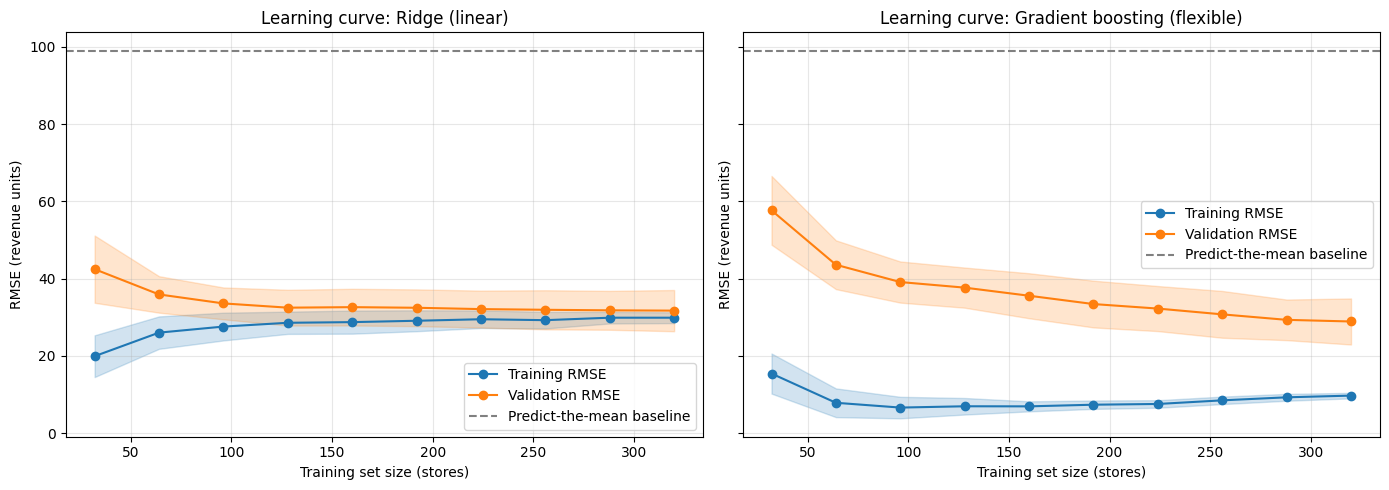


=== More stores vs. better features ===
Doubling stores (400 -> 800) is projected to change validation RMSE by ~-0.78 for the linear model (fold-to-fold noise is +/- 5.34).
Flexible model vs. linear on the same features: +9% validation RMSE reduction.


In [10]:
"""
Learning-curve diagnostic for a small tabular regression (~400 rows, ~12 predictors).

Usage:
    # X: (n_samples, n_features) array or DataFrame, y: (n_samples,) array/Series
    from learning_curve_diagnostic import run_diagnostic
    run_diagnostic(X, y)

Swap in your own estimator via run_diagnostic(X, y, model=your_pipeline).
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, RepeatedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor


def default_model():
    # Regularized linear baseline. Scaling lives inside the pipeline so it is
    # refit on each training fold -- fitting the scaler on all of X first
    # would leak validation statistics into training.
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25)))


def compute_curve(model, X, y, cv, train_sizes):
    sizes, train_scores, val_scores = learning_curve(
        model, X, y,
        train_sizes=train_sizes,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        shuffle=True,
        random_state=0,
    )
    # sklearn returns negated RMSE (higher = better); flip to plain RMSE.
    return sizes, -train_scores, -val_scores


def plot_curve(ax, sizes, train_err, val_err, baseline_rmse, title):
    tr_mean, tr_std = train_err.mean(axis=1), train_err.std(axis=1)
    va_mean, va_std = val_err.mean(axis=1), val_err.std(axis=1)

    ax.plot(sizes, tr_mean, "o-", color="tab:blue", label="Training RMSE")
    ax.fill_between(sizes, tr_mean - tr_std, tr_mean + tr_std, color="tab:blue", alpha=0.2)
    ax.plot(sizes, va_mean, "o-", color="tab:orange", label="Validation RMSE")
    ax.fill_between(sizes, va_mean - va_std, va_mean + va_std, color="tab:orange", alpha=0.2)

    # Reference line: error of predicting the training mean for every store.
    # Judging the LEVEL needs a yardstick; a validation curve sitting near this
    # line means the predictors explain little of revenue.
    ax.axhline(baseline_rmse, ls="--", color="gray", label="Predict-the-mean baseline")

    ax.set_xlabel("Training set size (stores)")
    ax.set_ylabel("RMSE (revenue units)")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)

    # ------------------------------------------------------------------
    # HOW TO READ THIS PLOT
    #
    # The GAP (validation minus training error) measures VARIANCE:
    #   how much the model's fit depends on which particular stores it saw.
    #   - Large gap: the model memorizes training stores and does not
    #     generalize -> high variance / overfitting.
    #   - A gap that is still SHRINKING at the right edge means the curves
    #     have not met yet; more stores would keep pulling validation error
    #     down. This is the one situation where more data clearly pays.
    #   - Other variance fixes: stronger regularization, fewer features,
    #     a simpler model.
    #
    # The LEVEL both curves converge toward measures BIAS (plus
    # irreducible noise): the best error this model family can reach with
    # these features, no matter how many stores you add.
    #   - If both curves are close together AND high (near the baseline,
    #     or above the error your business can tolerate), the model is
    #     underfitting -> high bias.
    #   - More data will NOT help a high-bias model: the curves have
    #     already met, and adding rows just confirms the same plateau.
    #   - Bias fixes: better/new features (the information isn't in X),
    #     or a more flexible model (the information is in X but the model
    #     can't express it). Comparing a flexible model below separates
    #     those two cases.
    # ------------------------------------------------------------------


def tail_slope_per_doubling(sizes, val_mean, k=4):
    # Fit validation RMSE against log2(n) over the last k points. The slope
    # is the RMSE change per doubling of the data -- a rough, optimistic
    # forecast of what doubling the number of stores would buy.
    k = min(k, len(sizes))
    slope, _ = np.polyfit(np.log2(sizes[-k:]), val_mean[-k:], 1)
    return slope


def diagnose(name, sizes, train_err, val_err, baseline_rmse):
    tr_end = train_err.mean(axis=1)[-1]
    va_mean = val_err.mean(axis=1)
    va_end = va_mean[-1]
    va_std_end = val_err.std(axis=1)[-1]

    gap = va_end - tr_end
    rel_gap = gap / va_end                       # share of val error that is "gap"
    skill = 1 - va_end / baseline_rmse            # 0 = no better than the mean, 1 = perfect
    per_doubling = tail_slope_per_doubling(sizes, va_mean)

    print(f"\n=== {name} ===")
    print(f"Final training RMSE:     {tr_end:,.2f}")
    print(f"Final validation RMSE:   {va_end:,.2f}  (+/- {va_std_end:,.2f} across folds)")
    print(f"Baseline (mean) RMSE:    {baseline_rmse:,.2f}")
    print(f"Gap:                     {gap:,.2f}  ({rel_gap:.0%} of validation error)")
    print(f"Skill vs. baseline:      {skill:.0%} RMSE reduction")
    print(f"Val RMSE change per doubling of stores (tail fit): {per_doubling:+,.2f}")

    # Heuristic thresholds -- adjust to your tolerance. These are rules of
    # thumb for reading the plot, not statistical tests.
    still_improving = per_doubling < -va_std_end   # gain exceeds fold noise
    big_gap = rel_gap > 0.25
    low_skill = skill < 0.5

    if big_gap and still_improving:
        verdict = ("HIGH VARIANCE, data-limited: curves have not converged and validation "
                   "error is still falling. More stores should help; also try stronger "
                   "regularization in the meantime.")
    elif big_gap:
        verdict = ("HIGH VARIANCE, but validation has flattened: more stores alone gives "
                   "diminishing returns. Regularize or simplify first.")
    elif low_skill:
        verdict = ("HIGH BIAS: curves have converged at a high level. More stores will not "
                   "move this; invest in features (or model flexibility -- see comparison).")
    else:
        verdict = ("Reasonably balanced: small gap and decent skill. Remaining error is "
                   "mostly bias + noise; feature work is the lever if you need more.")
    print("Diagnosis:", verdict)
    return dict(train=tr_end, val=va_end, gap=gap, skill=skill,
                per_doubling=per_doubling, val_std=va_std_end)


def run_diagnostic(X, y, model=None, compare_flexible=True, n_repeats=3, save_path=None):
    X = np.asarray(X)
    y = np.asarray(y).ravel()

    # 5-fold repeated 3x: with 400 rows each validation fold is only 80 stores,
    # so a single split is noisy. Repetition gives the shaded bands meaning.
    cv = RepeatedKFold(n_splits=5, n_repeats=n_repeats, random_state=42)
    # Start at ~10% (~32 stores); smaller fits on 12 predictors are unstable.
    train_sizes = np.linspace(0.1, 1.0, 10)

    baseline_rmse = -cross_val_score(
        DummyRegressor(), X, y, cv=cv, scoring="neg_root_mean_squared_error"
    ).mean()

    models = {"Ridge (linear)": model or default_model()}
    if compare_flexible:
        # Flexible nonlinear model on the SAME features. Interpretation:
        #   - If it converges much lower than Ridge -> the signal is in X but
        #     nonlinear/interactive; model capacity, not data, was the limit.
        #   - If it plateaus at about the same level -> the features themselves
        #     lack the information; new features are the only bias fix.
        #   - If its gap is much larger -> 400 stores is too few for this
        #     model; it would be the one that benefits from more data.
        models["Gradient boosting (flexible)"] = HistGradientBoostingRegressor(
            max_depth=3, learning_rate=0.05, max_iter=300,
            min_samples_leaf=10, l2_regularization=1.0, random_state=0,
        )

    fig, axes = plt.subplots(1, len(models), figsize=(7 * len(models), 5), sharey=True)
    axes = np.atleast_1d(axes)
    results = {}
    for ax, (name, m) in zip(axes, models.items()):
        sizes, tr, va = compute_curve(m, X, y, cv, train_sizes)
        plot_curve(ax, sizes, tr, va, baseline_rmse, f"Learning curve: {name}")
        results[name] = diagnose(name, sizes, tr, va, baseline_rmse)

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150)
    plt.show()

    # ---- Investment summary: more stores vs. better features -------------
    lin = results["Ridge (linear)"]
    print("\n=== More stores vs. better features ===")
    print(f"Doubling stores (400 -> 800) is projected to change validation RMSE by "
          f"~{lin['per_doubling']:+,.2f} for the linear model "
          f"(fold-to-fold noise is +/- {lin['val_std']:,.2f}).")
    if compare_flexible:
        gb = results["Gradient boosting (flexible)"]
        improvement = (lin["val"] - gb["val"]) / lin["val"]
        print(f"Flexible model vs. linear on the same features: {improvement:+.0%} "
              f"validation RMSE reduction.")
        if improvement > 0.10:
            print("-> Nonlinear structure exists in current features: cheap win from "
                  "feature engineering (interactions, transforms) or a nonlinear model.")
        elif max(lin["skill"], gb["skill"]) < 0.5:
            print("-> Both models plateau at a similar, high level: the missing signal "
                  "isn't in X. New data SOURCES (features) beat new rows.")
    return results

results_lc = run_diagnostic(X, y)

*Your answer here.*

**1. Does the learning curve agree with Phase 3?**

Yes. For the linear Ridge model with all 17 predictors, training RMSE is 29.87 and validation RMSE is 31.70. The gap is only 1.83, so the curves have nearly converged. Doubling the sample size is expected to reduce validation RMSE by only 0.78, which is small compared with the fold-to-fold variation of ±5.34.

However, the model's error is still high. Since the true equation has an RMSE of about 22.8, much of the remaining error comes from model bias rather than random noise. The linear model cannot capture the nonlinear relationship between floor area and revenue. This agrees with the high-bias problem found in Phase 3.


**2. Comparison with gradient boosting**

Gradient boosting reaches a validation RMSE of 28.89 and is still improving by 6.74 per doubling of the sample size. However, its training-validation gap is much larger at 19.19, which suggests high variance with only 400 stores.

In comparison, the OLS model with a three-knot spline in floor area reaches a nested-CV RMSE of 25.3. This shows that a better model specification can outperform a more flexible method.


**3. More data or better features?**

Better features. The linear model's learning curve is almost flat, so adding more stores is unlikely to improve it much. Adding a spline feature reduced prediction error by about 6 without requiring any additional data. More data would mainly help flexible models learn the nonlinear relationship that the spline already captures.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [11]:
# (b) 300 columns of pure noise as X, Phase 1 revenue as y
X = pd.DataFrame(rng.normal(size=(N_STORES, 300)), columns=[f'noise_{i+1}' for i in range(300)])
y = stores['revenue']

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.05


In [13]:
from sklearn.pipeline import make_pipeline

# the same three steps, but inside a Pipeline so they are refitted within each fold
pipe = make_pipeline(StandardScaler(), SelectKBest(f_regression, k=20), LinearRegression())
pipe_scores = cross_val_score(pipe, X, y, cv=5, scoring="r2")
print(f"Pipeline R^2: {pipe_scores.mean():.2f}")
print(f"Gap: {scores.mean() - pipe_scores.mean():.2f}")

Pipeline R^2: -0.28
Gap: 0.33


*Your answer here.*

(a) The main problem is SelectKBest. It selects the 20 columns most correlated with y using all 400 stores, including the validation folds. This means the feature selection already uses information from the data that will later be used to evaluate the model. Cross-validation does not account for this step.

StandardScaler is not a problem here. It does not use y, and OLS with an intercept gives the same predictions after scaling. Fitting it on the full sample instead of within each fold does not change the predictions.

(b) When the analyst's code is run with 300 noise columns as X and Phase 1 revenue as y, it reports R² = 0.05. When all three steps are placed inside a Pipeline and refitted within each fold, R² drops to −0.28. The difference is 0.33. Since the features are pure noise, the negative R² is the more honest result: the model does worse than simply predicting the mean.

(c) It is a special case of the Step 3.2 problem: in both, data used to score the model also shaped an earlier choice (which model there, which features here), so the score is optimistic, only here the choice happens entirely outside the cross-validation loop.

### Task 4.3: The handover note (3 pts)

*Your answer here.*

### Store Revenue Forecast (v2)

**What it predicts.**  
The model predicts monthly store revenue (in $'000) based on floor area, foot traffic, local median income, and years open. It uses a piecewise-linear spline for floor area to account for slower revenue growth at larger stores.

**Expected prediction error.**  
Nested cross-validation gives an expected RMSE of about **\$25k per store per month**, with a 95% range of **\$22k to \$29k** and an R² of about **0.93**. The model also had an RMSE of $23.9k on a new simulated month. However, predictions are less accurate for larger stores because their revenue is more variable.

**Limitations.**  
The model may not work well for stores outside the observed size range of 6k to 86k sq ft because it must extrapolate beyond the data. It may also become less accurate if the store population or the relationship between revenue and its predictors changes, such as in a new market. The model still over-predicts revenue for the largest 10% of stores by about \$21k per month, although this is an improvement from about \$42k with the old model. These forecasts should be checked against actual revenue.

**Next steps.**  
I would try weighted least squares to account for the higher noise among large stores, add prediction intervals that are wider for larger stores, and check prediction errors every month against the expected \$25k RMSE. I removed `staff_count` because it did not improve prediction, not simply because it had a high VIF.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

*Model and date:*

Claude Opus 5.5
Nov 18

*Prompt:*
```
[Prep] Act as a machine learning engineer who diagnoses model
performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and
about 12 predictors. Write Python that produces a learning curve --
training and validation error as a function of training set size --
and interprets it to distinguish a high-bias problem from a
high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot
both curves on one axis with a shaded band for variability across
folds.

[Mechanism Check] Add comments explaining what the GAP between the two
curves indicates versus what the LEVEL both converge to indicates, and
what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better
features is the higher-return investment.
```

*Reply:*
```
"""
Learning-curve diagnostic for a small tabular regression (~400 rows, ~12 predictors).

Usage:
    # X: (n_samples, n_features) array or DataFrame, y: (n_samples,) array/Series
    from learning_curve_diagnostic import run_diagnostic
    run_diagnostic(X, y)

Swap in your own estimator via run_diagnostic(X, y, model=your_pipeline).
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, RepeatedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor


def default_model():
    # Regularized linear baseline. Scaling lives inside the pipeline so it is
    # refit on each training fold -- fitting the scaler on all of X first
    # would leak validation statistics into training.
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25)))


def compute_curve(model, X, y, cv, train_sizes):
    sizes, train_scores, val_scores = learning_curve(
        model, X, y,
        train_sizes=train_sizes,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        shuffle=True,
        random_state=0,
    )
    # sklearn returns negated RMSE (higher = better); flip to plain RMSE.
    return sizes, -train_scores, -val_scores


def plot_curve(ax, sizes, train_err, val_err, baseline_rmse, title):
    tr_mean, tr_std = train_err.mean(axis=1), train_err.std(axis=1)
    va_mean, va_std = val_err.mean(axis=1), val_err.std(axis=1)

    ax.plot(sizes, tr_mean, "o-", color="tab:blue", label="Training RMSE")
    ax.fill_between(sizes, tr_mean - tr_std, tr_mean + tr_std, color="tab:blue", alpha=0.2)
    ax.plot(sizes, va_mean, "o-", color="tab:orange", label="Validation RMSE")
    ax.fill_between(sizes, va_mean - va_std, va_mean + va_std, color="tab:orange", alpha=0.2)

    # Reference line: error of predicting the training mean for every store.
    # Judging the LEVEL needs a yardstick; a validation curve sitting near this
    # line means the predictors explain little of revenue.
    ax.axhline(baseline_rmse, ls="--", color="gray", label="Predict-the-mean baseline")

    ax.set_xlabel("Training set size (stores)")
    ax.set_ylabel("RMSE (revenue units)")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)

    # ------------------------------------------------------------------
    # HOW TO READ THIS PLOT
    #
    # The GAP (validation minus training error) measures VARIANCE:
    #   how much the model's fit depends on which particular stores it saw.
    #   - Large gap: the model memorizes training stores and does not
    #     generalize -> high variance / overfitting.
    #   - A gap that is still SHRINKING at the right edge means the curves
    #     have not met yet; more stores would keep pulling validation error
    #     down. This is the one situation where more data clearly pays.
    #   - Other variance fixes: stronger regularization, fewer features,
    #     a simpler model.
    #
    # The LEVEL both curves converge toward measures BIAS (plus
    # irreducible noise): the best error this model family can reach with
    # these features, no matter how many stores you add.
    #   - If both curves are close together AND high (near the baseline,
    #     or above the error your business can tolerate), the model is
    #     underfitting -> high bias.
    #   - More data will NOT help a high-bias model: the curves have
    #     already met, and adding rows just confirms the same plateau.
    #   - Bias fixes: better/new features (the information isn't in X),
    #     or a more flexible model (the information is in X but the model
    #     can't express it). Comparing a flexible model below separates
    #     those two cases.
    # ------------------------------------------------------------------


def tail_slope_per_doubling(sizes, val_mean, k=4):
    # Fit validation RMSE against log2(n) over the last k points. The slope
    # is the RMSE change per doubling of the data -- a rough, optimistic
    # forecast of what doubling the number of stores would buy.
    k = min(k, len(sizes))
    slope, _ = np.polyfit(np.log2(sizes[-k:]), val_mean[-k:], 1)
    return slope


def diagnose(name, sizes, train_err, val_err, baseline_rmse):
    tr_end = train_err.mean(axis=1)[-1]
    va_mean = val_err.mean(axis=1)
    va_end = va_mean[-1]
    va_std_end = val_err.std(axis=1)[-1]

    gap = va_end - tr_end
    rel_gap = gap / va_end                       # share of val error that is "gap"
    skill = 1 - va_end / baseline_rmse            # 0 = no better than the mean, 1 = perfect
    per_doubling = tail_slope_per_doubling(sizes, va_mean)

    print(f"\n=== {name} ===")
    print(f"Final training RMSE:     {tr_end:,.2f}")
    print(f"Final validation RMSE:   {va_end:,.2f}  (+/- {va_std_end:,.2f} across folds)")
    print(f"Baseline (mean) RMSE:    {baseline_rmse:,.2f}")
    print(f"Gap:                     {gap:,.2f}  ({rel_gap:.0%} of validation error)")
    print(f"Skill vs. baseline:      {skill:.0%} RMSE reduction")
    print(f"Val RMSE change per doubling of stores (tail fit): {per_doubling:+,.2f}")

    # Heuristic thresholds -- adjust to your tolerance. These are rules of
    # thumb for reading the plot, not statistical tests.
    still_improving = per_doubling < -va_std_end   # gain exceeds fold noise
    big_gap = rel_gap > 0.25
    low_skill = skill < 0.5

    if big_gap and still_improving:
        verdict = ("HIGH VARIANCE, data-limited: curves have not converged and validation "
                   "error is still falling. More stores should help; also try stronger "
                   "regularization in the meantime.")
    elif big_gap:
        verdict = ("HIGH VARIANCE, but validation has flattened: more stores alone gives "
                   "diminishing returns. Regularize or simplify first.")
    elif low_skill:
        verdict = ("HIGH BIAS: curves have converged at a high level. More stores will not "
                   "move this; invest in features (or model flexibility -- see comparison).")
    else:
        verdict = ("Reasonably balanced: small gap and decent skill. Remaining error is "
                   "mostly bias + noise; feature work is the lever if you need more.")
    print("Diagnosis:", verdict)
    return dict(train=tr_end, val=va_end, gap=gap, skill=skill,
                per_doubling=per_doubling, val_std=va_std_end)


def run_diagnostic(X, y, model=None, compare_flexible=True, n_repeats=3, save_path=None):
    X = np.asarray(X)
    y = np.asarray(y).ravel()

    # 5-fold repeated 3x: with 400 rows each validation fold is only 80 stores,
    # so a single split is noisy. Repetition gives the shaded bands meaning.
    cv = RepeatedKFold(n_splits=5, n_repeats=n_repeats, random_state=42)
    # Start at ~10% (~32 stores); smaller fits on 12 predictors are unstable.
    train_sizes = np.linspace(0.1, 1.0, 10)

    baseline_rmse = -cross_val_score(
        DummyRegressor(), X, y, cv=cv, scoring="neg_root_mean_squared_error"
    ).mean()

    models = {"Ridge (linear)": model or default_model()}
    if compare_flexible:
        # Flexible nonlinear model on the SAME features. Interpretation:
        #   - If it converges much lower than Ridge -> the signal is in X but
        #     nonlinear/interactive; model capacity, not data, was the limit.
        #   - If it plateaus at about the same level -> the features themselves
        #     lack the information; new features are the only bias fix.
        #   - If its gap is much larger -> 400 stores is too few for this
        #     model; it would be the one that benefits from more data.
        models["Gradient boosting (flexible)"] = HistGradientBoostingRegressor(
            max_depth=3, learning_rate=0.05, max_iter=300,
            min_samples_leaf=10, l2_regularization=1.0, random_state=0,
        )

    fig, axes = plt.subplots(1, len(models), figsize=(7 * len(models), 5), sharey=True)
    axes = np.atleast_1d(axes)
    results = {}
    for ax, (name, m) in zip(axes, models.items()):
        sizes, tr, va = compute_curve(m, X, y, cv, train_sizes)
        plot_curve(ax, sizes, tr, va, baseline_rmse, f"Learning curve: {name}")
        results[name] = diagnose(name, sizes, tr, va, baseline_rmse)

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150)
    plt.show()

    # ---- Investment summary: more stores vs. better features -------------
    lin = results["Ridge (linear)"]
    print("\n=== More stores vs. better features ===")
    print(f"Doubling stores (400 -> 800) is projected to change validation RMSE by "
          f"~{lin['per_doubling']:+,.2f} for the linear model "
          f"(fold-to-fold noise is +/- {lin['val_std']:,.2f}).")
    if compare_flexible:
        gb = results["Gradient boosting (flexible)"]
        improvement = (lin["val"] - gb["val"]) / lin["val"]
        print(f"Flexible model vs. linear on the same features: {improvement:+.0%} "
              f"validation RMSE reduction.")
        if improvement > 0.10:
            print("-> Nonlinear structure exists in current features: cheap win from "
                  "feature engineering (interactions, transforms) or a nonlinear model.")
        elif max(lin["skill"], gb["skill"]) < 0.5:
            print("-> Both models plateau at a similar, high level: the missing signal "
                  "isn't in X. New data SOURCES (features) beat new rows.")
    return results


if __name__ == "__main__":
    # Smoke test on synthetic data with the same shape as the real problem.
    # Replace with:  run_diagnostic(X, y)
    rng = np.random.default_rng(0)
    X_demo = rng.normal(size=(400, 12))
    y_demo = (50 + X_demo[:, :4] @ np.array([8, -5, 3, 2])
              + 4 * X_demo[:, 4] * X_demo[:, 5] + rng.normal(scale=10, size=400))
    run_diagnostic(X_demo, y_demo, save_path="learning_curve_demo.png")
```


I can’t give you the verdict yet because your X and y didn’t come through. There’s no uploaded file and nothing in the chat. So I wrote the script, checked that it runs on synthetic data with the same shape (400 × 12), and here’s how to read what it prints once you call run_diagnostic(X, y) on your data. If you upload the data as a CSV with the revenue column named, I’ll run it and give you the actual answer.

What the script does. It builds learning curves with 5-fold cross-validation repeated 3 times. A single 80-store validation fold is too noisy to trust, so the shaded bands are the standard deviation across those 15 fits. It plots training and validation RMSE on one axis, with a dashed line for a model that always predicts the average revenue. That line gives you something to compare the error level against. It then prints a diagnosis based on three numbers:

The gap at full size. A large gap means high variance.
Skill compared with the baseline. If both curves converge close to the baseline, that’s high bias.
The slope of validation error against log₂(n) over the last few points. This is a rough estimate of what doubling the number of stores would gain.

It also fits a regularized gradient-boosting model on the same features. That comparison answers the question your feature decision depends on:

If the flexible model converges much lower than Ridge, the signal is already in your 12 predictors and the linear model just can’t capture it. The fix is cheap: add interactions or transforms, or switch to a nonlinear model.
If both models level off at the same high error, the information isn’t in X at all. Only new data sources will help.

The decision rule:

More stores are worth buying only if the gap is large and validation error is still dropping at 320 training rows by more than the fold-to-fold noise.
Better features are the right investment if the curves have already met at a level you can’t accept.

With ~12 predictors and 400 rows, a regularized linear model usually converges well before 320 rows. So in practice, the answer is often features, but your data decides that.

One caution, which the synthetic test showed. The demo data has a lot of pure noise built in. The script correctly reported “high bias, features over rows,” but that floor came from noise, not missing features, so no feature would fix it. The level the curves converge to is bias plus irreducible noise, and a learning curve can’t separate the two. Before paying for new data sources, check whether there are plausible drivers of revenue you aren’t measuring yet, such as foot traffic, local demographics, or competitor proximity. If there aren’t any, the floor may be the real limit of what can be predicted.




*What I changed:*

- The model could not access my data, so it first ran the code on its own simulated data with 12 predictors and a baseline RMSE of 15.04. I then reran it in Colab with my Phase 1 X and y, which have 400 stores, 17 predictors, and a baseline RMSE of 99.01.



- I replaced the synthetic-data test at the end of the code with run_diagnostic(X, y). This allowed the learning curve to use my actual store data instead of the demo data.



- I did not agree with the code's conclusion that the linear model was "reasonably balanced." It compares the validation error with the predict-the-mean baseline, but the known noise floor is about 23. Since the validation RMSE levels off at 31.7, the model still has high bias. This also matches my Phase 3 results.

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.